# Morphological Black Top-Hat for Crevasse Enhancement

## Objective
Explore morphological black top-hat as an image enhancement method
to make dark crevasse features more visible in NISAR satellite images.

## Method
Black top-hat highlights dark features that are smaller than a
specified structuring element.

We will:
1. Load a sample NISAR radar image.
2. Apply morphological black top-hat.
3. Compare different structuring element sizes.
4. Evaluate whether crevasses become easier to identify.

In [5]:
import sys
from pathlib import Path

# Add the project's src directory to the Python path
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "src"))

from utils.inference_strategies.nisar_preprocessing import load_nisar_tile

import matplotlib.pyplot as plt
import numpy as np

# Use the project's configured data directory
data_root = Path(os.environ.get("DATA_DIR", "/data"))
data_dir = data_root / "nisar_data" / "nisar_gcov_pig"

# Use the same NISAR frame for all comparisons
frame_name = (
    "NISAR_L2_PR_GCOV_024_077_A_140_4005_SHSH_A_"
    "20260701T135211_20260701T135247_P05023_N_F_J_001.h5"
)

file_path = data_dir / frame_name

if not file_path.is_file():
    raise FileNotFoundError(
        f"Required NISAR frame not found: {file_path}\n"
        "Download the frame and check your DATA_DIR setting."
    )

# Tile settings
tile_size = 4096
tiles = [(4, 2), (5, 3)]


# Test loading the first tile using the shared NISAR loader
image_db, valid = load_nisar_tile(
    file_path=file_path,
    row=4,
    col=2,
    tile_size=tile_size,
)

print("File:", file_path.name)
print("Image shape:", image_db.shape)
print("Data type:", image_db.dtype)
print("Valid pixels:", valid.sum())

File: NISAR_L2_PR_GCOV_024_077_A_140_4005_SHSH_A_20260701T135211_20260701T135247_P05023_N_F_J_001.h5
Image shape: (4096, 4096)
Data type: float32
Valid pixels: 16777197


In [6]:
import sys
from pathlib import Path

# Add the project's src directory to Python's import path
project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root / "src"))

from utils.inference_strategies.black_tophat import apply_black_tophat  # noqa: E402

print("Black top-hat function imported successfully!")

Black top-hat function imported successfully!


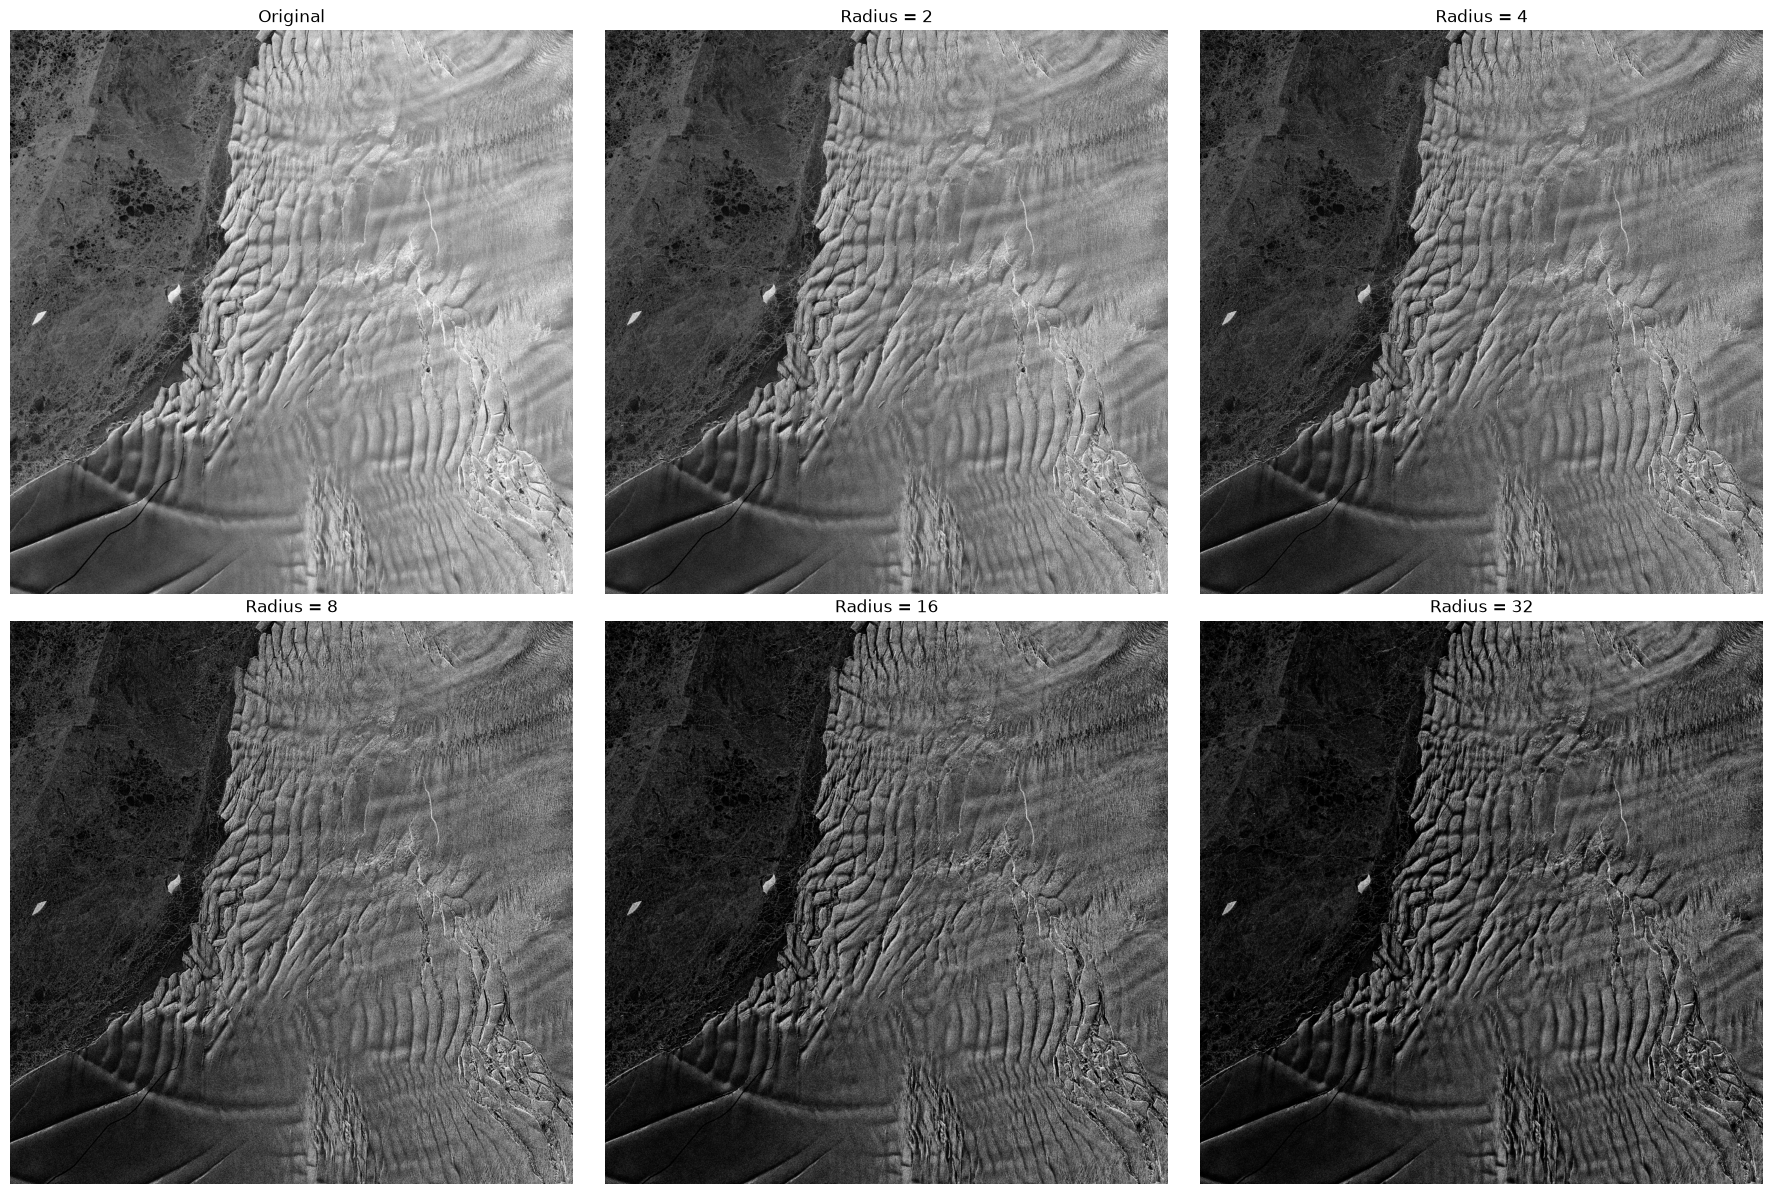

In [8]:
# Hyperparameters to test
radii = [2, 4, 8, 16, 32]

# Fill invalid pixels before enhancement
median = np.nanmedian(image_db)
image_clean = np.where(valid, image_db, median)

# Set display limits
vmin, vmax = np.percentile(image_db[valid], [1, 99])

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# Original image
axes[0].imshow(image_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Original")
axes[0].axis("off")

# Test different radii
for i, radius in enumerate(radii, start=1):
    response = apply_black_tophat(image_clean, radius=radius)

    enhanced = image_clean - response
    enhanced[~valid] = np.nan

    axes[i].imshow(enhanced, cmap="gray", vmin=vmin, vmax=vmax)
    axes[i].set_title(f"Radius = {radius}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)

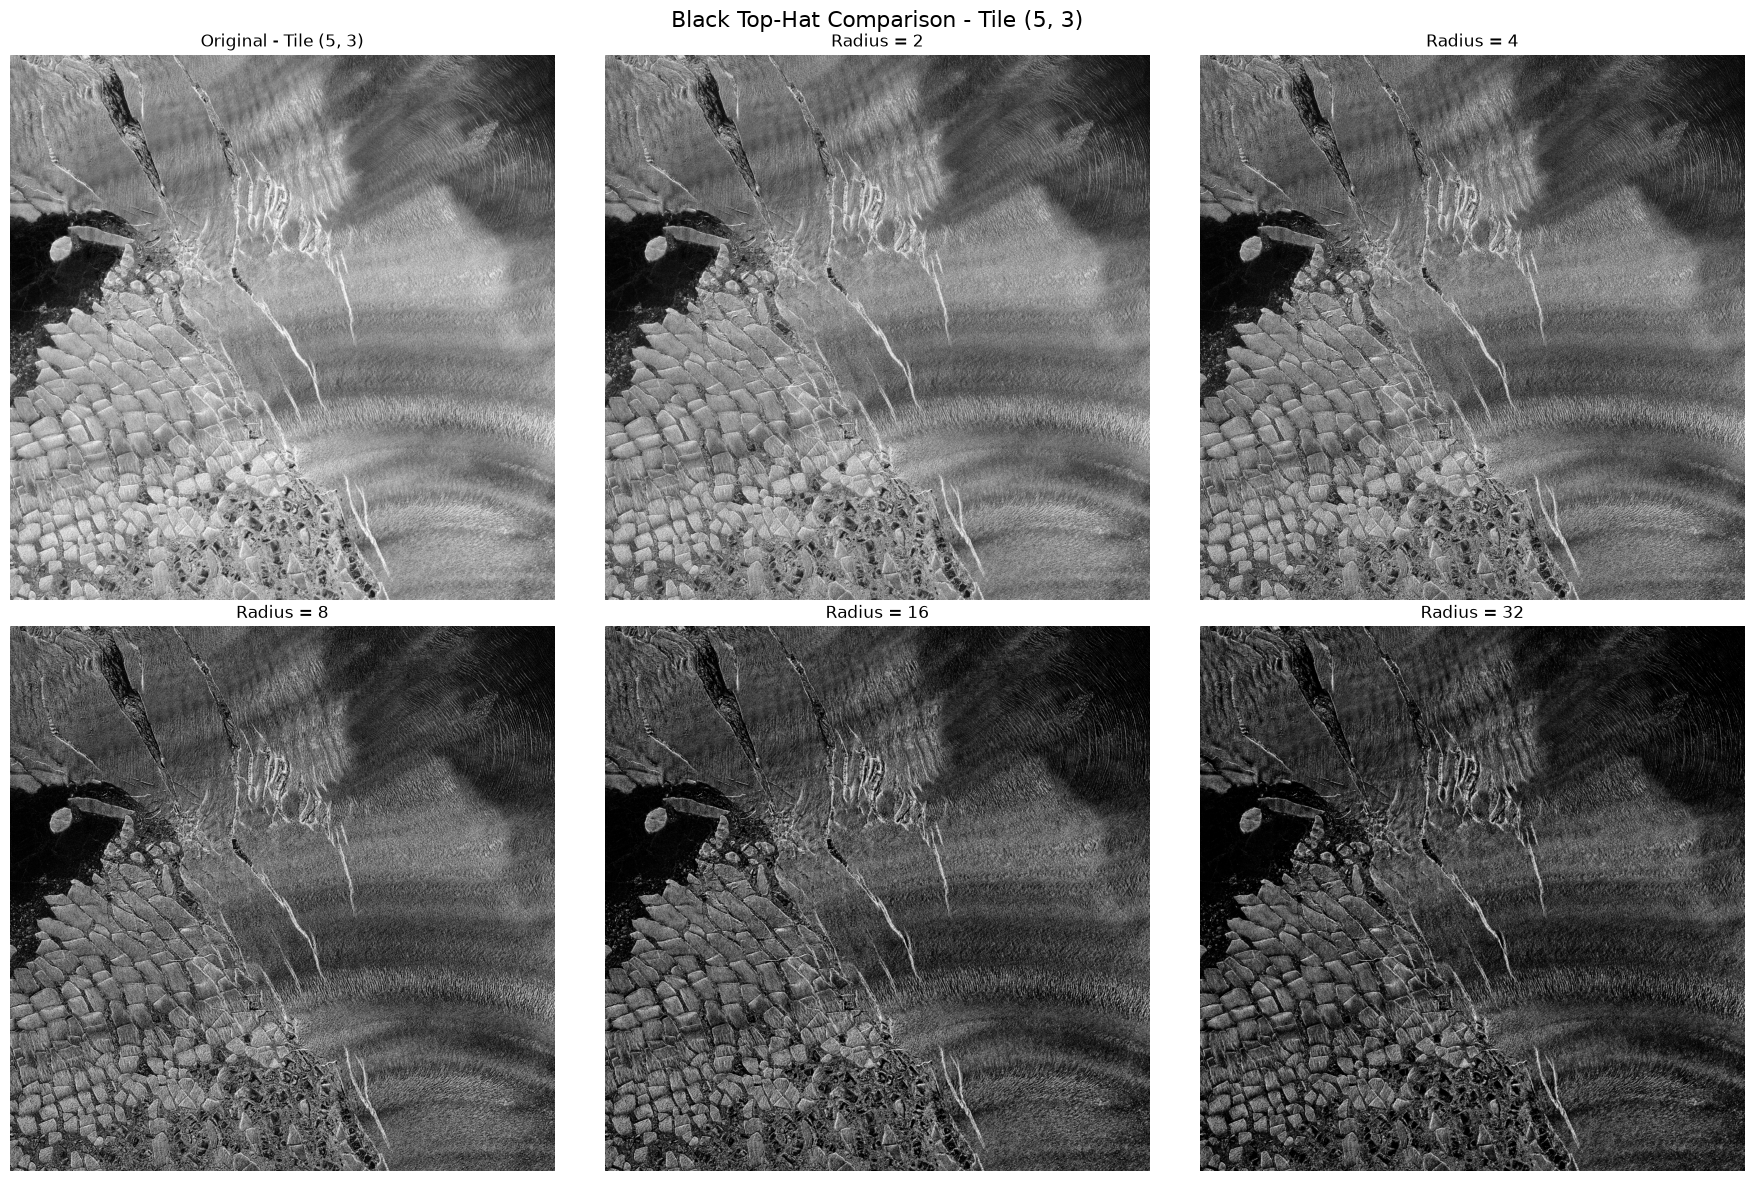

In [9]:
# Load tile (5, 3) using the shared NISAR loader
image_db_53, valid_53 = load_nisar_tile(
    file_path=file_path,
    row=5,
    col=3,
    tile_size=tile_size,
)

# Fill invalid pixels temporarily with the median
median_53 = np.nanmedian(image_db_53)
image_clean_53 = np.where(valid_53, image_db_53, median_53)

# Set display limits
vmin_53, vmax_53 = np.percentile(image_db_53[valid_53], [1, 99])

# Compare the same radii
radii = [2, 4, 8, 16, 32]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

# Original image
axes[0].imshow(image_db_53, cmap="gray", vmin=vmin_53, vmax=vmax_53)
axes[0].set_title("Original - Tile (5, 3)")
axes[0].axis("off")

# Test different radii
for i, radius in enumerate(radii, start=1):
    response = apply_black_tophat(image_clean_53, radius=radius)

    enhanced = image_clean_53 - response
    enhanced[~valid_53] = np.nan

    axes[i].imshow(enhanced, cmap="gray", vmin=vmin_53, vmax=vmax_53)
    axes[i].set_title(f"Radius = {radius}")
    axes[i].axis("off")

plt.suptitle("Black Top-Hat Comparison - Tile (5, 3)", fontsize=16)
plt.tight_layout()
plt.show()
plt.close(fig)

### Hyperparameter Selection

Morphological black top-hat was tested with radii of 2, 4, 8, 16, and 32 on two NISAR image tiles, (4, 2) and (5, 3).

Smaller radii (2 and 4) produced relatively subtle changes, while larger radii (8–32) increasingly darkened the images and emphasized background textures. Although larger radii enhanced some dark features more strongly, they also introduced unwanted changes to the surrounding surface.

**Radius = 4 was selected** because it provided a reasonable balance between enhancing fine dark features and preserving the original image structure across both tiles. This selection was based on visual comparison rather than quantitative detection performance.